In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import os
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [37]:
df = pd.read_csv("Churn_Modelling.csv")

In [38]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [39]:
df.shape

(10000, 14)

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [41]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [42]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [43]:
df.duplicated().sum()

np.int64(0)

In [44]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [45]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [46]:
df.drop(columns = ['RowNumber','CustomerId','Surname'], inplace = True)

In [47]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [48]:
df.shape

(10000, 11)

In [56]:
df = pd.get_dummies(df, columns = ['Geography','Gender'], drop_first = True)

In [49]:
#from sklearn.preprocessing import LabelEncoder

In [50]:
#tr = LabelEncoder()

In [51]:
#le.fit(["Geography", "Gender"])

LabelEncoder()

In [52]:
#encoded = le.transform(["Geography", "Gender"])
print(encoded)

[1 0]


In [55]:
#df.head()

In [57]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [58]:
X = df.drop(columns = ["Exited"])
y = df["Exited"]

In [60]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [62]:
from sklearn.preprocessing import StandardScaler

In [64]:
sc = StandardScaler()
X_train_scaler = sc.fit_transform(X_train)
X_test_scaler = sc.fit_transform(X_test)

In [65]:
X_train_scaler

array([[ 0.35649971, -0.6557859 ,  0.34567966, ..., -0.57946723,
        -0.57638802,  0.91324755],
       [-0.20389777,  0.29493847, -0.3483691 , ...,  1.72572313,
        -0.57638802,  0.91324755],
       [-0.96147213, -1.41636539, -0.69539349, ..., -0.57946723,
         1.73494238,  0.91324755],
       ...,
       [ 0.86500853, -0.08535128, -1.38944225, ..., -0.57946723,
        -0.57638802, -1.09499335],
       [ 0.15932282,  0.3900109 ,  1.03972843, ..., -0.57946723,
        -0.57638802,  0.91324755],
       [ 0.47065475,  1.15059039, -1.38944225, ...,  1.72572313,
        -0.57638802,  0.91324755]], shape=(8000, 11))

In [66]:
X_test_scaler

array([[-5.12501721e-01, -6.77299309e-01, -6.98445493e-01, ...,
         1.73668197e+00, -5.63491843e-01,  9.09111664e-01],
       [-2.36046598e-01,  3.84298354e-01, -1.38035469e+00, ...,
        -5.75810666e-01, -5.63491843e-01,  9.09111664e-01],
       [-4.61306328e-01,  4.80807232e-01, -3.57490896e-01, ...,
        -5.75810666e-01,  1.77464858e+00, -1.09997489e+00],
       ...,
       [ 8.59534812e-01,  7.70333868e-01,  6.65372897e-01, ...,
        -5.75810666e-01, -5.63491843e-01, -1.09997489e+00],
       [ 4.70449825e-01, -9.66825944e-01, -3.57490896e-01, ...,
        -5.75810666e-01, -5.63491843e-01,  9.09111664e-01],
       [-1.84851205e-01, -1.73715981e-03, -1.38035469e+00, ...,
         1.73668197e+00, -5.63491843e-01,  9.09111664e-01]],
      shape=(2000, 11))

In [69]:
model = Sequential()
model.add(Dense(3, activation = 'sigmoid', input_dim = 11))
model.add(Dense(1, activation = 'sigmoid'))

In [70]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 3)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40 (160.00 B)

 Trainable params: 40 (160.00 B)

 Non-trainable params: 0 (0.00 B)

In [88]:
model.compile(loss = 'binary_crossentropy', optimizer = 'Adam', metrics = ["accuracy"])

In [99]:
history = model.fit(X_train_scaler, y_train, epochs = 100, validation_split =0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8472 - loss: 0.3679 - val_accuracy: 0.8506 - val_loss: 0.3666
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8470 - loss: 0.3679 - val_accuracy: 0.8506 - val_loss: 0.3664
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8470 - loss: 0.3678 - val_accuracy: 0.8500 - val_loss: 0.3663
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8469 - loss: 0.3678 - val_accuracy: 0.8506 - val_loss: 0.3662
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8470 - loss: 0.3676 - val_accuracy: 0.8519 - val_loss: 0.3661
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8477 - loss: 0.3675 - val_accuracy: 0.8519 - val_loss: 0.3661
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8477 - loss: 0.3674 - val_accuracy: 0.8525 - val_loss: 0.3660
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8477 - loss: 0.3674 - val_accu

In [90]:
model.layers[0].get_weights()

[array([[ 1.1761584e-01, -2.3386857e-01,  2.3905177e-02],
        [-6.2104011e-01, -1.5807089e-01, -2.8206108e+00],
        [-2.7975691e-03, -9.1305859e-02, -1.5720028e-02],
        [-1.9317245e+00,  1.2921391e+00, -4.4852316e-01],
        [-3.6132226e+00,  1.0500406e+00, -5.6246465e-01],
        [-3.1114332e-02,  5.6550433e-03, -3.2158535e-02],
        [-1.4897147e-01, -1.6283071e+00, -5.4294807e-01],
        [-9.1940306e-02,  7.8331523e-02,  1.7230894e-02],
        [ 1.2882200e+00, -8.8859536e-02,  2.7587229e-01],
        [ 1.4352401e-01,  6.8134293e-02,  5.8932066e-02],
        [ 3.1129718e-01, -9.8140478e-01,  4.1919291e-02]], dtype=float32),
 array([-2.6133888 , -0.14125471,  0.49588317], dtype=float32)]

In [91]:
y_log = model.predict(X_test_scaler)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [92]:
model.predict(X_train_scaler)

250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


array([[0.00888104],
       [0.12580946],
       [0.1742773 ],
       ...,
       [0.21862833],
       [0.31733727],
       [0.47355446]], shape=(8000, 1), dtype=float32)

In [96]:
y_pred = np.where(y_log > 0.5,1,0)

In [97]:
from sklearn.metrics import accuracy_score

In [98]:
accuracy_score(y_test, y_pred)

0.8435

In [100]:
history.history

{'accuracy': [0.8471875190734863,
  0.8470312356948853,
  0.8470312356948853,
  0.846875011920929,
  0.8470312356948853,
  0.84765625,
  0.84765625,
  0.84765625,
  0.8475000262260437,
  0.8475000262260437,
  0.84765625,
  0.8471875190734863,
  0.8467187285423279,
  0.8465625047683716,
  0.846875011920929,
  0.8479687571525574,
  0.8487499952316284,
  0.84765625,
  0.8481249809265137,
  0.8475000262260437,
  0.8473437428474426,
  0.8471875190734863,
  0.8479687571525574,
  0.8482812643051147,
  0.8485937714576721,
  0.8490625023841858,
  0.8485937714576721,
  0.8489062786102295,
  0.8481249809265137,
  0.8490625023841858,
  0.8496875166893005,
  0.8487499952316284,
  0.8495312333106995,
  0.8493750095367432,
  0.8495312333106995,
  0.8492187261581421,
  0.8500000238418579,
  0.8492187261581421,
  0.8501562476158142,
  0.8500000238418579,
  0.8504687547683716,
  0.8503124713897705,
  0.8506249785423279,
  0.8500000238418579,
  0.8496875166893005,
  0.8506249785423279,
  0.85046875476837

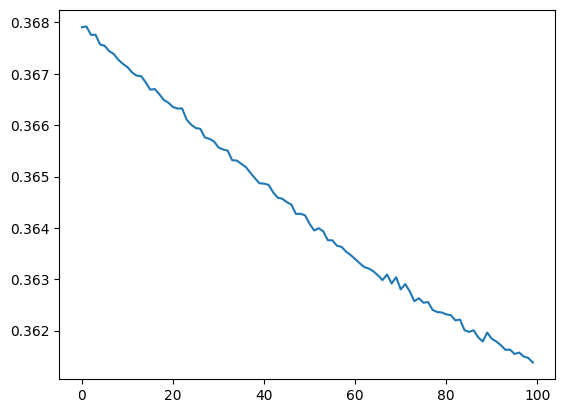

In [102]:
plt.plot(history.history['loss'])
plt.show()

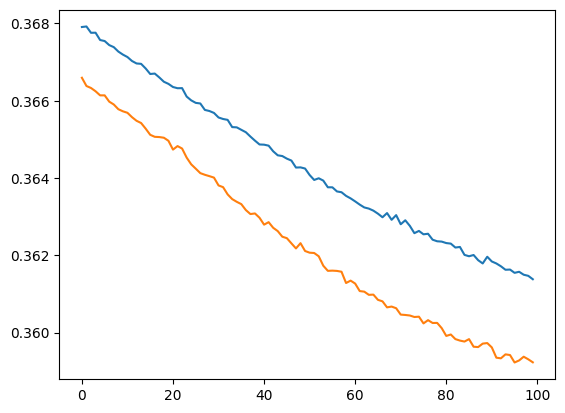

In [103]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.show()

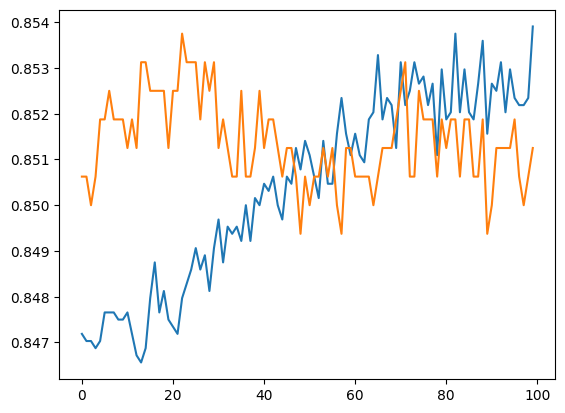

In [104]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.show()